In [1]:
import matplotlib.pyplot as plt
from matplotlib import rc, rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
from scipy.stats import exponnorm, norm
import pandas as pd
import math
from pathlib import Path
import re
import sys

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)
    
IMT_DATADIR = Path("../../Data/Exp_Intermitotic_Times")

rcParams.update({'figure.autolayout': True})

# add path to fit functions
sys.path.insert(0, "./../../Python")
from fits import emg_fit_func, fit_EMGMM


In [3]:
file_location = os.path.join(IMT_DATADIR,'*imt_*.csv')
filenames = glob.glob(file_location)
filenames.sort()
filenames

['..\\..\\Data\\Exp_Intermitotic_Times\\02kpa_dmso_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\02kpa_erl_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\06kpa_dmso_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\06kpa_erl_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\4kpa_dmso_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\4kpa_erl_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\55kpa_dmso_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\55kpa_erl_imt_181017.csv']

In [4]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)  # histogram bin centers 

In [23]:
cond=pd.Series(data={'stiff':0.2, 'drug':'DMSO'})
SM = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['S-M_t']
SM = SM[~np.isnan(SM)]
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = norm.fit(data)



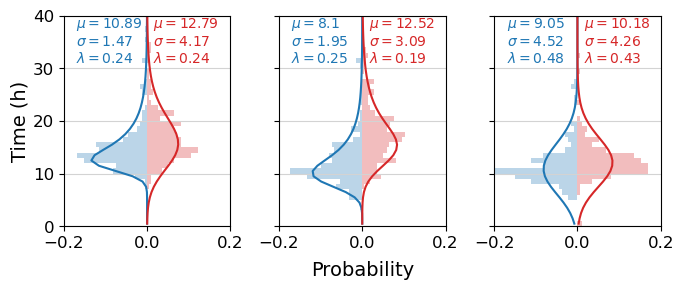

In [58]:
win = 21
pol = 2
size = (7.25,3.25)
c1 = "tab:blue"
c2 = "tab:red"
xmin = -0.2
xmax = 0.2
ymin = 0
ymax = 40

fig, axes = plt.subplots(1, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

cond=pd.Series(data={'stiff':0.2, 'drug':'DMSO'})
SM = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['S-M_t']
SM = SM[~np.isnan(SM)]
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[0].plot(fitted_curve, centers, color=c1)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(-0.17, 31, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)


cond=pd.Series(data={'stiff':0.2, 'drug':'ERL'})
SM = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['S-M_t']
SM = SM[~np.isnan(SM)]
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0].plot(fitted_curve, centers, color=c2)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(0.015, 31, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)

cond=pd.Series(data={'stiff':4, 'drug':'DMSO'})
SM = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['S-M_t']
SM = SM[~np.isnan(SM)]
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[1].plot(fitted_curve, centers, color=c1)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(-0.17, 31, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

cond=pd.Series(data={'stiff':4, 'drug':'ERL'})
SM = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['S-M_t']
SM = SM[~np.isnan(SM)]
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
params1=params
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1].plot(fitted_curve, centers, color=c2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(0.015, 31, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)

cond=pd.Series(data={'stiff':55, 'drug':'DMSO'})
SM = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['S-M_t']
SM = SM[~np.isnan(SM)]
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[2].plot(fitted_curve, centers, color=c1)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(-0.17, 31, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

cond=pd.Series(data={'stiff':55, 'drug':'ERL'})
SM = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['S-M_t']
SM = SM[~np.isnan(SM)]
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data, method='MLE')
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2].plot(fitted_curve, centers, color=c2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(0.015, 31, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)



ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Probability', labelpad=25)
ax.set_ylabel('Time (h)', labelpad=25)
#fig.tight_layout(rect=(0, 0, 1, 1))

fig1b_fn = Path(SAVEDIR, 'SuppFig1.svg')

if SAVEFILES and (OVERWRITE or not fig1b_fn.exists()):
    plt.savefig(fig1b_fn, bbox_inches='tight')
else:
    plt.figure()

In [48]:
params1

(1.6721529286019572, 12.518121243191441, 3.0915441820922918)

In [53]:
init = (1.5, 12, 3)
bounds = [(0, 5), (8, 15), (0,5)]